<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/07_Recommendation_Systems/notebooks/06_Hybrid_Movie_Recommendation_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 34: Hybrid Movie Recommendation System

## Objective
Build a hybrid recommendation engine by combining
collaborative filtering and content-based filtering.

## Techniques
- User-Based Collaborative Filtering
- Content-Based Filtering
- TF-IDF
- Cosine Similarity
- Score Normalization
- Weighted Hybrid Recommendation
- Precision@10 Evaluation

## Dataset
MovieLens Latest Small

## Libraries
Python, Pandas, NumPy, Scikit-learn

In [1]:
#Import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer

import zipfile
import urllib.request
import os

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#Download and load MovieLens
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

if not os.path.exists("ml-latest-small"):
    urllib.request.urlretrieve(url, "movielens.zip")

    with zipfile.ZipFile("movielens.zip", "r") as zip_ref:
        zip_ref.extractall(".")

ratings = pd.read_csv("ml-latest-small/ratings.csv")
movies = pd.read_csv("ml-latest-small/movies.csv")

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)

display(ratings.head())
display(movies.head())

Ratings shape: (100836, 4)
Movies shape: (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
#Train-test split
train_ratings, test_ratings = train_test_split(
    ratings,
    test_size=0.20,
    random_state=42
)

print("Training ratings:", train_ratings.shape)
print("Testing ratings:", test_ratings.shape)

Training ratings: (80668, 4)
Testing ratings: (20168, 4)


In [4]:
#Select popular movies
movie_counts = (
    train_ratings.groupby("movieId")
    .size()
    .sort_values(ascending=False)
)

top_movie_ids = movie_counts.head(500).index

train_top = train_ratings[
    train_ratings["movieId"].isin(top_movie_ids)
].copy()

test_top = test_ratings[
    test_ratings["movieId"].isin(top_movie_ids)
].copy()

print("Selected movies:", len(top_movie_ids))
print("Training interactions:", train_top.shape)
print("Testing interactions:", test_top.shape)

Selected movies: 500
Training interactions: (35076, 4)
Testing interactions: (8527, 4)


In [5]:
#Create the user–movie matrix
user_movie_matrix = train_top.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

user_movie_filled = user_movie_matrix.fillna(0)

print("User-movie matrix shape:", user_movie_matrix.shape)

display(user_movie_matrix.head())

User-movie matrix shape: (608, 500)


movieId,1,2,3,6,7,10,11,16,17,19,...,96079,99114,106782,109374,109487,112852,116797,122882,134130,134853
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,5.0,NaN,3.0,NaN,NaN,5.0,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
#Calculate user similarity
user_similarity = cosine_similarity(
    user_movie_filled
)

user_similarity_df = pd.DataFrame(
    user_similarity,
    index=user_movie_matrix.index,
    columns=user_movie_matrix.index
)

display(user_similarity_df.iloc[:5, :5])

userId,1,2,3,4,5
userId,,,,,
1,1.000000,0.029592,0.152386,0.328444,0.201118
2,0.029592,1.000000,0.000000,0.009673,0.000000
3,0.152386,0.000000,1.000000,0.000000,0.030703
4,0.328444,0.009673,0.000000,1.000000,0.102345
5,0.201118,0.000000,0.030703,0.102345,1.000000


In [7]:
#Create collaborative prediction function
def collaborative_predictions(user_id, k=20):

    if user_id not in user_movie_matrix.index:
        return pd.Series(dtype=float)

    # Similarity scores for the target user
    similarities = user_similarity_df[user_id].drop(
        index=user_id,
        errors="ignore"
    )

    # Keep positive similarities
    similarities = similarities[similarities > 0]

    # Select the top k similar users
    neighbors = similarities.nlargest(k)

    if neighbors.empty:
        return pd.Series(dtype=float)

    # Get ratings from similar users
    neighbor_ratings = user_movie_matrix.loc[
        neighbors.index
    ]

    # Replace missing ratings with zero for weighted summation
    rating_values = neighbor_ratings.fillna(0)

    # Identify which ratings were actually observed
    observed_mask = neighbor_ratings.notna().astype(float)

    # Weighted sum of ratings for each movie
    weighted_sum = rating_values.T.dot(neighbors)

    # Sum of similarities only where ratings exist
    similarity_sum = observed_mask.T.dot(neighbors)

    # Divide weighted rating sum by relevant similarity sum
    predictions = weighted_sum.div(
        similarity_sum.replace(0, np.nan)
    )

    # Use the training mean when no suitable neighbors rated a movie
    predictions = predictions.fillna(
        train_top["rating"].mean()
    )

    return predictions.clip(0.5, 5.0)

In [8]:
#Clean genres
movies["genres_clean"] = (
    movies["genres"]
    .replace("(no genres listed)", "")
    .fillna("")
)

display(
    movies[["title", "genres", "genres_clean"]].head()
)

,title,genres,genres_clean
0,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Adventure|Animation|Children|Comedy|Fantasy
1,Jumanji (1995),Adventure|Children|Fantasy,Adventure|Children|Fantasy
2,Grumpier Old Men (1995),Comedy|Romance,Comedy|Romance
3,Waiting to Exhale (1995),Comedy|Drama|Romance,Comedy|Drama|Romance
4,Father of the Bride Part II (1995),Comedy,Comedy


In [9]:
#Convert genres into TF-IDF features
tfidf = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

tfidf_matrix = tfidf.fit_transform(
    movies["genres_clean"]
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Genre features:", len(tfidf.get_feature_names_out()))

TF-IDF matrix shape: (9742, 21)
Genre features: 21


In [10]:
#Create movie ID mapping
movie_id_to_index = {
    movie_id: index
    for index, movie_id in enumerate(movies["movieId"])
}

print("Movie mapping created.")

Movie mapping created.


In [11]:
#Build user preference profile
def build_user_profile(user_id, min_rating=4.0):

    user_history = train_ratings[
        train_ratings["userId"] == user_id
    ]

    liked_movies = user_history[
        user_history["rating"] >= min_rating
    ]

    if liked_movies.empty:
        return None

    liked_ids = [
        movie_id
        for movie_id in liked_movies["movieId"]
        if movie_id in movie_id_to_index
    ]

    if not liked_ids:
        return None

    liked_indices = [
        movie_id_to_index[movie_id]
        for movie_id in liked_ids
    ]

    # Use the corresponding ratings as profile weights
    weights = (
        liked_movies.set_index("movieId")
        .loc[liked_ids, "rating"]
        .to_numpy()
    )

    # Combine the TF-IDF vectors into a user profile
    profile = tfidf_matrix[liked_indices].multiply(
        weights.reshape(-1, 1)
    ).sum(axis=0)

    profile = np.asarray(profile) / weights.sum()

    return profile

In [12]:
#Calculate content-based scores
def content_predictions(user_id):

    profile = build_user_profile(user_id)

    if profile is None:
        return pd.Series(dtype=float)

    # Calculate similarity between user profile and all movies
    scores = cosine_similarity(
        profile,
        tfidf_matrix
    ).flatten()

    content_scores = pd.Series(
        scores,
        index=movies["movieId"]
    )

    return content_scores

In [13]:
#Create a normalization function
def min_max_normalize(series):

    if series.empty:
        return series

    min_value = series.min()
    max_value = series.max()

    if max_value == min_value:
        return pd.Series(
            0.0,
            index=series.index
        )

    return (series - min_value) / (
        max_value - min_value
    )

In [14]:
#Build the hybrid recommendation function
def hybrid_recommendations(
    user_id,
    top_n=10,
    alpha=0.5
):

    # Validate the hybrid weight
    if not 0 <= alpha <= 1:
        raise ValueError("alpha must be between 0 and 1.")

    # Get collaborative filtering predictions
    cf_scores = collaborative_predictions(user_id)

    # Get content-based similarity scores
    content_scores = content_predictions(user_id)

    # Check whether a content profile could be created
    if content_scores.empty:
        print("Insufficient user history for a content profile.")
        return pd.DataFrame()

    # Restrict candidates to the selected 500 movies
    candidate_ids = list(top_movie_ids)

    # Exclude movies already rated by the user in training
    watched_movies = set(
        train_ratings.loc[
            train_ratings["userId"] == user_id,
            "movieId"
        ]
    )

    candidate_ids = [
        movie_id
        for movie_id in candidate_ids
        if movie_id not in watched_movies
    ]

    if not candidate_ids:
        return pd.DataFrame()

    # Align both model scores to the same candidate movies
    candidate_cf = cf_scores.reindex(
        candidate_ids
    ).fillna(train_top["rating"].mean())

    candidate_content = content_scores.reindex(
        candidate_ids
    ).fillna(0)

    # Normalize each model's scores
    normalized_cf = min_max_normalize(candidate_cf)
    normalized_content = min_max_normalize(candidate_content)

    # Calculate the combined hybrid score
    hybrid_score = (
        alpha * normalized_cf +
        (1 - alpha) * normalized_content
    )

    # Rank the movies by hybrid score
    results = pd.DataFrame({
        "movieId": candidate_ids,
        "collaborative_score": normalized_cf.values,
        "content_score": normalized_content.values,
        "hybrid_score": hybrid_score.values
    })

    results = results.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId"
    )

    results = results.sort_values(
        by="hybrid_score",
        ascending=False
    )

    return results[
        [
            "movieId",
            "title",
            "genres",
            "collaborative_score",
            "content_score",
            "hybrid_score"
        ]
    ].head(top_n).reset_index(drop=True)

In [15]:
#Generate hybrid recommendations
sample_user_id = train_top["userId"].iloc[0]

print("Recommendations for User:", sample_user_id)

hybrid_results = hybrid_recommendations(
    user_id=sample_user_id,
    top_n=10,
    alpha=0.5
)

display(hybrid_results)

Recommendations for User: 57


,movieId,title,genres,collaborative_score,content_score,hybrid_score
0,112852,Guardians of the Galaxy (2014),Action|Adventure|Sci-Fi,1.000000,0.751541,0.875771
1,51255,Hot Fuzz (2007),Action|Comedy|Crime|Mystery,1.000000,0.729107,0.864553
2,79132,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,1.000000,0.728467,0.864233
3,2395,Rushmore (1998),Comedy|Drama,0.803574,0.903926,0.853750
4,48774,Children of Men (2006),Action|Adventure|Drama|Sci-Fi|Thriller,0.751987,0.953367,0.852677
5,1247,"Graduate, The (1967)",Comedy|Drama|Romance,0.776111,0.906096,0.841104
6,5902,Adaptation (2002),Comedy|Drama|Romance,0.775968,0.906096,0.841032
7,2959,Fight Club (1999),Action|Crime|Drama|Thriller,0.870490,0.810662,0.840576
8,6711,Lost in Translation (2003),Comedy|Drama|Romance,0.764324,0.906096,0.835210
9,134853,Inside Out (2015),Adventure|Animation|Children|Comedy|Drama|Fantasy,0.921912,0.743997,0.832954


In [16]:
#Compare recommendation rankings
for alpha in [0.0, 0.25, 0.5, 0.75, 1.0]:

    print("\nAlpha:", alpha)

    results = hybrid_recommendations(
        sample_user_id,
        top_n=5,
        alpha=alpha
    )

    display(
        results[
            ["title", "collaborative_score",
             "content_score", "hybrid_score"]
        ]
    )


Alpha: 0.0


,title,collaborative_score,content_score,hybrid_score
0,Bad Boys (1995),0.384042,1.000000,1.000000
1,Mr. & Mrs. Smith (2005),0.466549,0.990782,0.990782
2,Blood Diamond (2006),0.635519,0.982363,0.982363
3,"Mummy Returns, The (2001)",0.144024,0.965304,0.965304
4,Sneakers (1992),0.364724,0.962474,0.962474



Alpha: 0.25


,title,collaborative_score,content_score,hybrid_score
0,Children of Men (2006),0.751987,0.953367,0.903022
1,Blood Diamond (2006),0.635519,0.982363,0.895652
2,Rushmore (1998),0.803574,0.903926,0.878838
3,Little Miss Sunshine (2006),0.640039,0.957117,0.877848
4,"Graduate, The (1967)",0.776111,0.906096,0.873600



Alpha: 0.5


,title,collaborative_score,content_score,hybrid_score
0,Guardians of the Galaxy (2014),1.000000,0.751541,0.875771
1,Hot Fuzz (2007),1.000000,0.729107,0.864553
2,Inception (2010),1.000000,0.728467,0.864233
3,Rushmore (1998),0.803574,0.903926,0.853750
4,Children of Men (2006),0.751987,0.953367,0.852677



Alpha: 0.75


,title,collaborative_score,content_score,hybrid_score
0,Guardians of the Galaxy (2014),1.000000,0.751541,0.937885
1,Hot Fuzz (2007),1.000000,0.729107,0.932277
2,Inception (2010),1.000000,0.728467,0.932117
3,Inside Out (2015),0.921912,0.743997,0.877433
4,Fight Club (1999),0.870490,0.810662,0.855533



Alpha: 1.0


,title,collaborative_score,content_score,hybrid_score
0,Guardians of the Galaxy (2014),1.000000,0.751541,1.000000
1,Inception (2010),1.000000,0.728467,1.000000
2,Hot Fuzz (2007),1.000000,0.729107,1.000000
3,Inside Out (2015),0.921912,0.743997,0.921912
4,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",0.896058,0.704313,0.896058


In [18]:
#Evaluate Precision@10
def evaluate_precision_at_10(alpha):

    precision_scores = []

    # Use users with positive ratings in the test data
    eligible_users = (
        test_top[test_top["rating"] >= 4.0]["userId"]
        .drop_duplicates()
        .head(100)
    )

    for user_id in eligible_users:

        recommendations = hybrid_recommendations(
            user_id=user_id,
            top_n=10,
            alpha=alpha
        )

        if recommendations.empty:
            continue

        recommended_ids = set(
            recommendations["movieId"]
        )

        relevant_ids = set(
            test_top[
                (test_top["userId"] == user_id) &
                (test_top["rating"] >= 4.0)
            ]["movieId"]
        )

        precision = len(
            recommended_ids.intersection(relevant_ids)
        ) / 10

        precision_scores.append(precision)

    if not precision_scores:
        return np.nan

    return np.mean(precision_scores)

In [19]:
#Compare three approaches
results = []

for alpha, model_name in [
    (0.0, "Content-Based"),
    (1.0, "Collaborative Filtering"),
    (0.5, "Hybrid Recommendation")
]:

    precision = evaluate_precision_at_10(alpha)

    results.append({
        "Model": model_name,
        "Precision@10": precision
    })

comparison = pd.DataFrame(results)

display(comparison)

,Model,Precision@10
0,Content-Based,0.057
1,Collaborative Filtering,0.068
2,Hybrid Recommendation,0.095


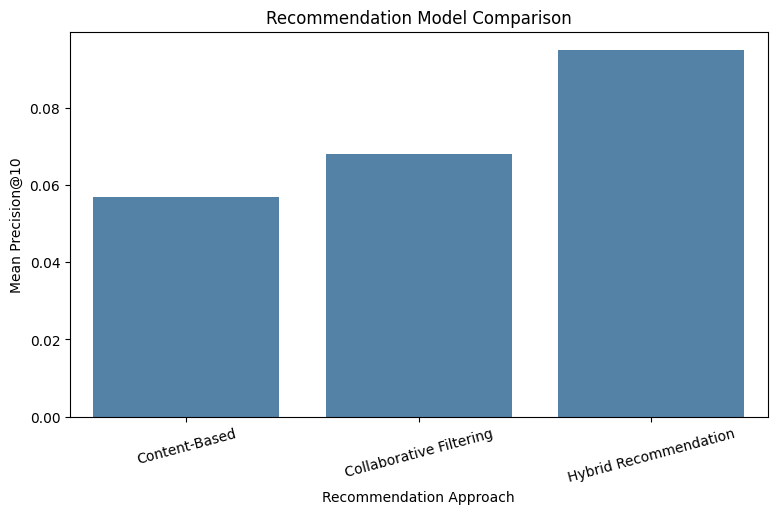

In [21]:
#Visualize the comparison
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Precision@10",
    color="steelblue"
)

plt.title("Recommendation Model Comparison")
plt.xlabel("Recommendation Approach")
plt.ylabel("Mean Precision@10")
plt.xticks(rotation=15)
plt.show()